In [ ]:
!pip install -q kagglehub


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (2).zip to archive (2).zip


In [ ]:
import zipfile
import os

zip_file = next(iter(uploaded.keys()))
extract_path = "/content/apple_dataset"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files_list in os.walk(extract_path):
    if files_list:
        print(root, "->", len(files_list), "files")

Dataset extracted successfully!
/content/apple_dataset -> 1 files
/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset/Strawberry/Fresh -> 220 files
/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset/Strawberry/Rotten -> 44 files
/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset/Banana/Fresh -> 33 files
/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset/Banana/Rotten -> 90 files
/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset/Apple/Fresh -> 124 files
/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset/Apple/Rotten -> 55 files


Fresh apples: 124
Rotten apples: 55


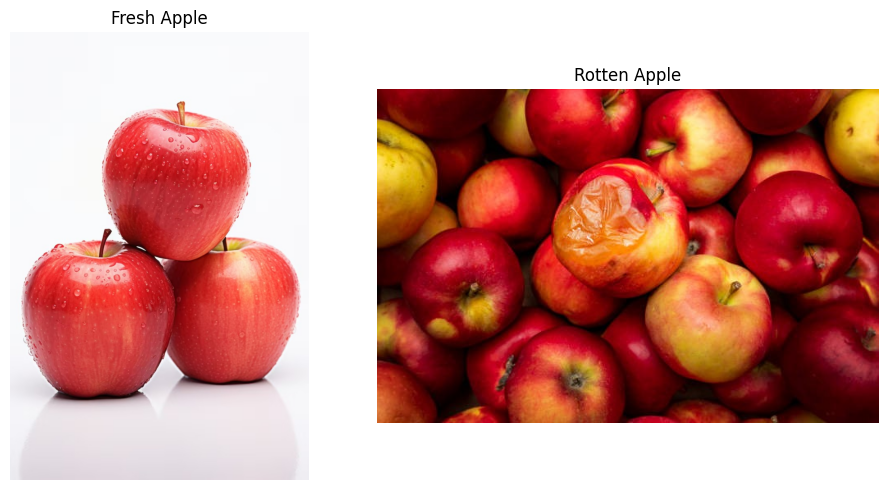

In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

# Dataset folders
base_path = "/content/apple_dataset/Fruit Freshness Dataset/Fruit Freshness Dataset"

fresh_path = os.path.join(base_path, "Apple", "Fresh")
rotten_path = os.path.join(base_path, "Apple", "Rotten")

# Display dataset counts
print("Fresh apples:", len(os.listdir(fresh_path)))
print("Rotten apples:", len(os.listdir(rotten_path)))

# Display sample images
plt.figure(figsize=(10, 5))

for i, (folder, label) in enumerate([
    (fresh_path, "Fresh Apple"),
    (rotten_path, "Rotten Apple")
]):
    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    sample = random.choice(image_files)
    image = Image.open(os.path.join(folder, sample)).convert("RGB")

    plt.subplot(1, 2, i + 1)
    plt.imshow(image)
    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 5: PREPARE DATA FOR CLASSIFICATION

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = (128, 128)
BATCH_SIZE = 16

# Load images and create an 80/20 split
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    base_path + "/Apple",
    classes=["Fresh", "Rotten"],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    seed=42
)

val_data = datagen.flow_from_directory(
    base_path + "/Apple",
    classes=["Fresh", "Rotten"],
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    seed=42,
    shuffle=False
)

print("Class labels:", train_data.class_indices)
print("Training images:", train_data.samples)
print("Validation images:", val_data.samples)

Found 137 images belonging to 2 classes.
Found 33 images belonging to 2 classes.
Class labels: {'Fresh': 0, 'Rotten': 1}
Training images: 137
Validation images: 33


In [ ]:
# STEP 6: BUILD THE CNN MODEL

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)

model = Sequential([
    Conv2D(32, (3, 3), activation="relu",
           input_shape=(128, 128, 3)),
    MaxPooling2D(2, 2),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),

    Flatten(),

    Dense(128, activation="relu"),
    Dropout(0.4),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# STEP 7: TRAIN THE APPLE CLASSIFICATION MODEL

EPOCHS = 15

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)

print("Model training completed!")

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 708ms/step - accuracy: 0.6788 - loss: 0.6939 - val_accuracy: 0.6970 - val_loss: 0.5054
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 609ms/step - accuracy: 0.8248 - loss: 0.3712 - val_accuracy: 0.9091 - val_loss: 0.2009
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 736ms/step - accuracy: 0.9124 - loss: 0.2468 - val_accuracy: 0.9091 - val_loss: 0.2197
Epoch 4/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 608ms/step - accuracy: 0.8978 - loss: 0.2265 - val_accuracy: 0.9394 - val_loss: 0.1944
Epoch 5/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 762ms/step - accuracy: 0.9781 - loss: 0.1230 - val_accuracy: 0.9394 - val_loss: 0.1135
Epoch 6/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 601ms/step - accuracy: 0.9416 - loss: 0.1207 - val_accuracy: 0.9091 - val_loss: 0.2129
Epoch 7/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 766ms/step - accuracy: 0.9781 - loss: 0.0689 - val_accuracy: 0.9394 - val_loss: 0.1164
Epoch 8/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 607ms/step - accuracy: 0.9854 - loss: 0.0367 - val_accuracy: 0.9394 - val_loss:

Saving apple.jpg to apple.jpg


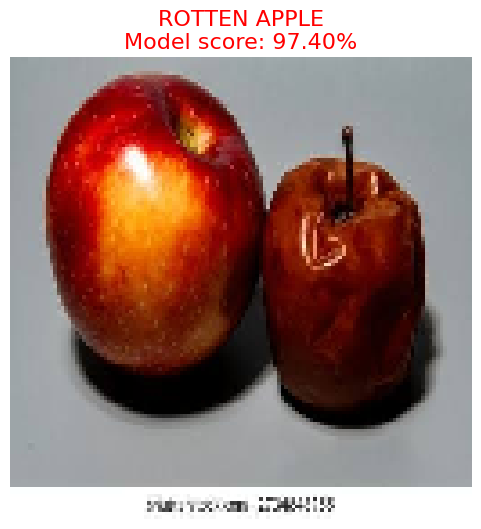

Prediction: ROTTEN APPLE
Model score: 97.40%


In [ ]:

# STEP 8: UPLOAD AN APPLE IMAGE AND PREDICT

from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# Upload an apple image from your computer
uploaded_image = files.upload()

# Get uploaded filename
image_path = next(iter(uploaded_image.keys()))

# Load and resize image
apple_image = load_img(image_path, target_size=IMG_SIZE)
apple_array = img_to_array(apple_image) / 255.0

# Prepare image for CNN
apple_input = np.expand_dims(apple_array, axis=0)

# Predict
prediction = float(model.predict(apple_input, verbose=0)[0][0])

# Class mapping: Fresh = 0, Rotten = 1
if prediction >= 0.5:
    label = "ROTTEN APPLE"
    confidence = prediction * 100
    result_color = "red"
else:
    label = "FRESH APPLE"
    confidence = (1 - prediction) * 100
    result_color = "green"

# Display uploaded image and prediction
plt.figure(figsize=(7, 6))
plt.imshow(apple_image)
plt.title(
    f"{label}\nModel score: {confidence:.2f}%",
    color=result_color,
    fontsize=16
)
plt.axis("off")
plt.show()

print("Prediction:", label)
print(f"Model score: {confidence:.2f}%")


In [ ]:

# IMPROVED APPLE CLASSIFIER: MOBILENETV2

import tensorflow as tf
from tensorflow.keras import layers, models

# Load a pretrained visual feature extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

# Build classifier
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Lambda(
        lambda x: tf.keras.applications.mobilenet_v2.preprocess_input(x * 255.0)
    ),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Train the new classifier
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

print("Transfer-learning model training completed.")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 654ms/step - accuracy: 0.7007 - loss: 0.6289 - val_accuracy: 0.6970 - val_loss: 0.5549
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 337ms/step - accuracy: 0.8613 - loss: 0.3746 - val_accuracy: 0.7879 - val_loss: 0.4537
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 340ms/step - accuracy: 0.9270 - loss: 0.2522 - val_accuracy: 0.7879 - val_loss: 0.4107
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 340ms/step - accuracy: 0.9416 - loss: 0.2069 - val_accuracy: 0.7879 - val_loss: 0.3998
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 477ms/step - accuracy: 0.9416 - loss: 0.1772 - val_accuracy: 0.7879 - val_loss: 0.3877
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 343ms/step - accuracy: 0.9416 - loss: 0.1669 - val_accuracy: 0.7879 - val_loss: 0.3767
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 338ms/step - accuracy: 0.9635 - loss: 0.1349 - val_accuracy: 0.7879 - val_loss: 0.3664
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 501ms/step - accuracy: 0.9635

Saving apple.jpg to apple (2).jpg


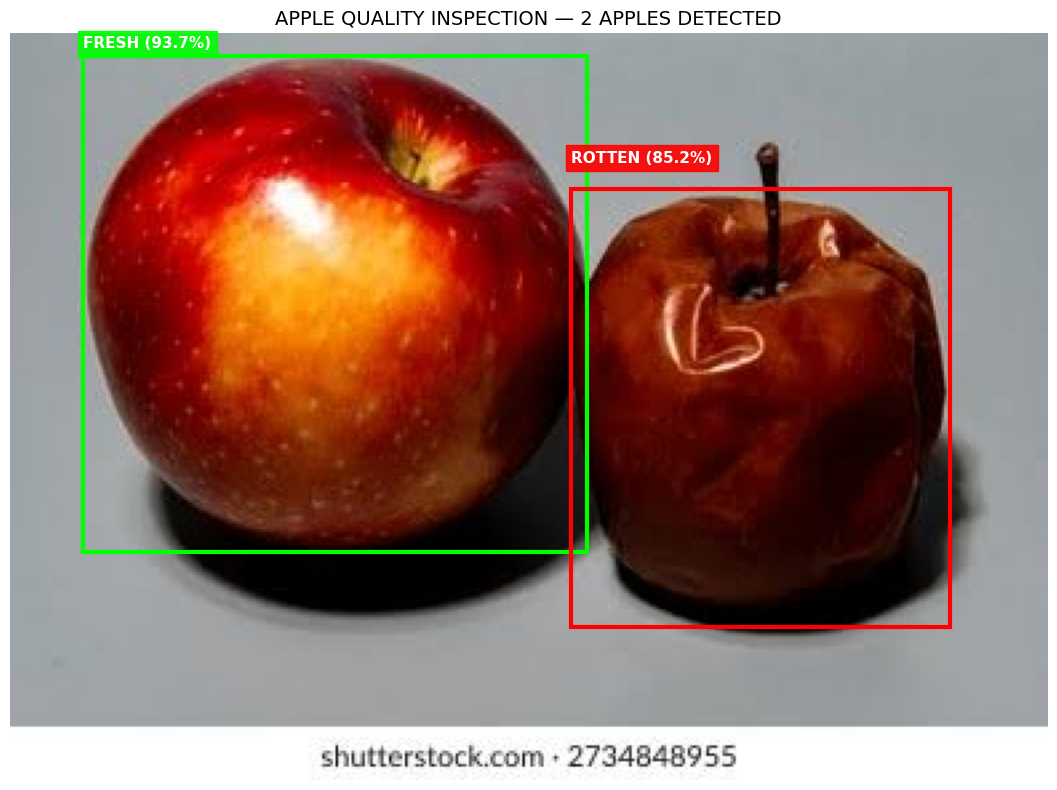

Total apples detected: 2
Green box = predicted fresh
Red box = predicted rotten


In [ ]:

# STEP 11: MULTIPLE APPLE DETECTION AND CLASSIFICATION

from ultralytics import YOLO
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 1. Load the pretrained apple detector
detector = YOLO("yolov8n.pt")

# 2. Upload the image containing multiple apples
uploaded_group = files.upload()
image_path = next(iter(uploaded_group.keys()))
image = Image.open(image_path).convert("RGB")

# 3. Detect objects in the image
results = detector.predict(
    source=image_path,
    conf=0.20,
    verbose=False
)[0]

# 4. Display image and prepare annotations
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)
ax.axis("off")

apple_count = 0

for box in results.boxes:
    class_id = int(box.cls[0])

    # COCO class: apple
    if detector.names[class_id] != "apple":
        continue

    # Get bounding-box coordinates
    x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

    # Crop the detected apple
    crop = image.crop((x1, y1, x2, y2))
    crop = crop.resize(IMG_SIZE)

    # Prepare the image for MobileNetV2
    apple_array = np.asarray(crop, dtype=np.float32) / 255.0
    apple_input = np.expand_dims(apple_array, axis=0)

    # Predict freshness
    score = float(model.predict(apple_input, verbose=0)[0][0])

    if score >= 0.5:
        label = "ROTTEN"
        confidence = score * 100
        color = "red"
    else:
        label = "FRESH"
        confidence = (1 - score) * 100
        color = "lime"

    # Draw a box around the apple
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=3,
        edgecolor=color,
        facecolor="none"
    )
    ax.add_patch(rect)

    # Add the predicted label
    ax.text(
        x1,
        max(y1 - 10, 5),
        f"{label} ({confidence:.1f}%)",
        color="white",
        fontsize=11,
        fontweight="bold",
        bbox=dict(
            facecolor=color,
            edgecolor=color,
            alpha=0.9,
            pad=4
        )
    )

    apple_count += 1

# 5. Show final simulation
plt.title(
    f"APPLE QUALITY INSPECTION — {apple_count} APPLES DETECTED",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Total apples detected:", apple_count)
print("Green box = predicted fresh")
print("Red box = predicted rotten")
